In [ ]:

%load_ext autoreload
%autoreload 2

import os
import sys
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sys.path.append(os.path.abspath('..'))
from src.transformadores import LimpiadorFormatosKaggle, CalculadorDistancia
from src.pipeline import construir_pipeline_preprocesamiento

print("=====================================================================")
print(" FASE 5: ENTRENAMIENTO Y EVALUACIÓN (ARQUITECTURA CORREGIDA)")
print("=====================================================================\n")

# 1. CARGAR DATOS
train_path = os.path.join('..', 'data', 'processed', 'train_processed.csv')
test_path = os.path.join('..', 'data', 'processed', 'test_processed.csv')

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# 2. APLICAR LIMPIEZA Y FEATURE ENGINEERING
print("Aplicando Transformadores Base (Regex y Haversine)...")
limpiador = LimpiadorFormatosKaggle()
calculador = CalculadorDistancia()

# Aplicar a Train
df_train_limpio = limpiador.transform(df_train)
df_train_final = calculador.transform(df_train_limpio)

# Aplicar a Test
df_test_limpio = limpiador.transform(df_test)
df_test_final = calculador.transform(df_test_limpio)

# 3. SEPARAR X e Y
X_train = df_train_final.drop(columns=['Time_taken(min)'])
y_train = df_train_final['Time_taken(min)'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

X_test = df_test_final.drop(columns=['Time_taken(min)'])
y_test = df_test_final['Time_taken(min)'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

# 4. PASAR POR LA PIPELINE FINAL DE SCIKIT-LEARN (Imputación + Encoding)
print("Ejecutando Pipeline Final (Imputación y Escalado)...")
pipeline_final = construir_pipeline_preprocesamiento()

X_train_preparado = pipeline_final.fit_transform(X_train)
X_test_preparado = pipeline_final.transform(X_test)

# 5. ENTRENAR MODELO
print("Entrenando Regresión Lineal...\n")
modelo_lr = LinearRegression()
modelo_lr.fit(X_train_preparado, y_train)

# 6. MÉTRICAS (TRAIN)
y_pred_train = modelo_lr.predict(X_train_preparado)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

print("--- 1. MÉTRICAS TRAIN SET ---")
print(f"MAE: {mae_train:.2f} minutos | R2: {r2_train:.4f}\n")

# 7. MÉTRICAS (TEST)
y_pred_test = modelo_lr.predict(X_test_preparado)
mae_test = mean_absolute_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print("--- 2. MÉTRICAS TEST SET (Prueba de Fuego) ---")
print(f"MAE: {mae_test:.2f} minutos | R2: {r2_test:.4f}\n")

# 8. ANÁLISIS DE OVERFITTING
diferencia_mae = abs(mae_train - mae_test)
print("--- 3. ANÁLISIS DE ESTABILIDAD ---")
print(f"Diferencia MAE (Train - Test): {diferencia_mae:.2f} minutos.")

if diferencia_mae < 0.5:
    print("EXCELENTE: Modelo estable. No hay Overfitting.")
else:
    print("ADVERTENCIA: Posible Overfitting.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
 FASE 5: ENTRENAMIENTO Y EVALUACIÓN (ARQUITECTURA CORREGIDA)

Aplicando Transformadores Base (Regex y Haversine)...
Ejecutando Pipeline Final (Imputación y Escalado)...
Entrenando Regresión Lineal...

--- 1. MÉTRICAS TRAIN SET ---
MAE: 4.97 minutos | R2: 0.5543

--- 2. MÉTRICAS TEST SET (Prueba de Fuego) ---
MAE: 4.94 minutos | R2: 0.5518

--- 3. ANÁLISIS DE ESTABILIDAD ---
Diferencia MAE (Train - Test): 0.03 minutos.
✓ EXCELENTE: Modelo estable. No hay Overfitting.


 FASE 5D: VALIDACIÓN VISUAL DEL RENDIMIENTO DEL MODELO



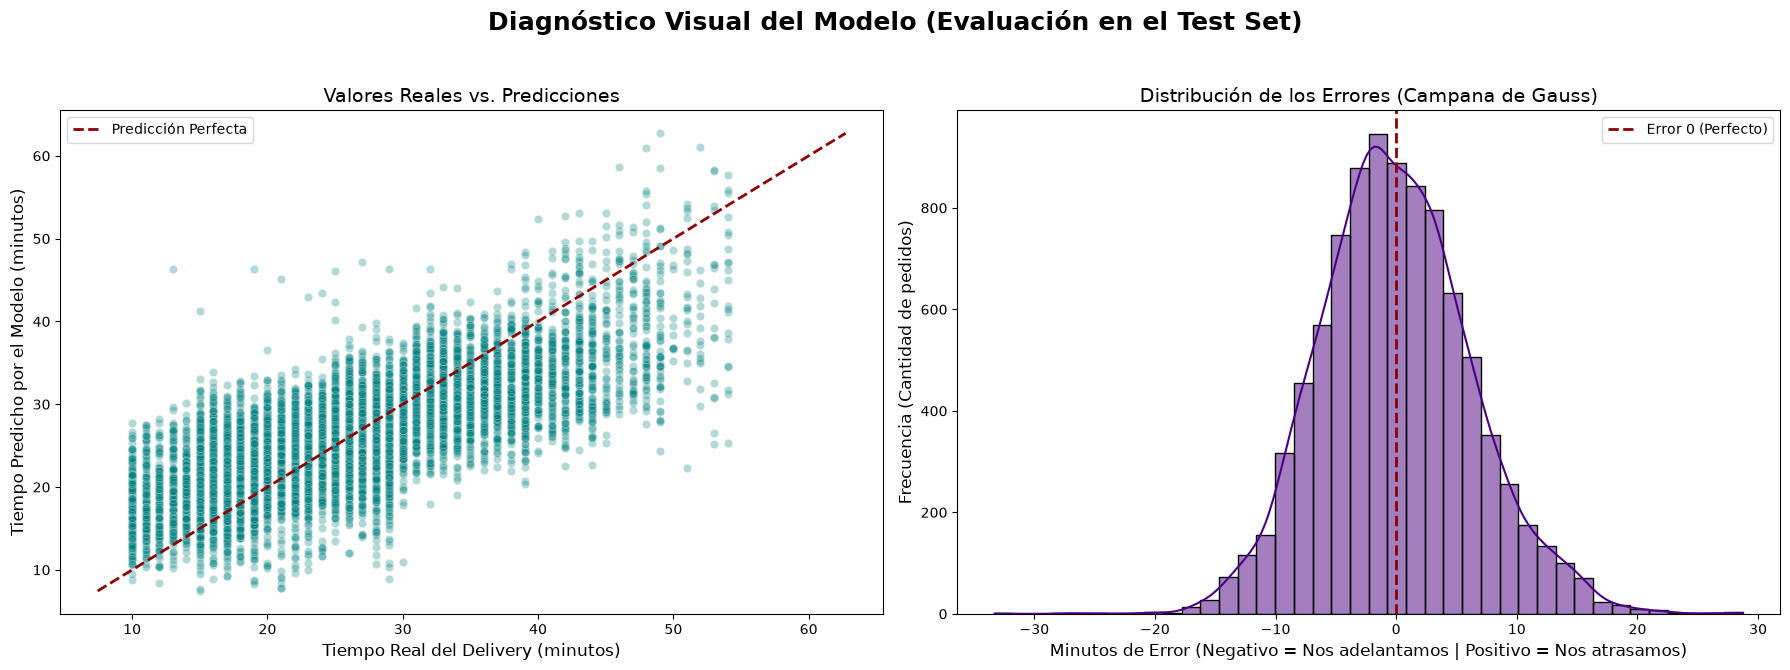

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=====================================================================")
print(" FASE 5: VALIDACIÓN VISUAL DEL RENDIMIENTO DEL MODELO")
print("=====================================================================\n")

# Calculamos las diferencias (entre la realidad y nuestra predicción)
residuos = y_test - y_pred_test

# Crear el lienzo
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Diagnóstico Visual del Modelo (Evaluación en el Test Set)', fontsize=18, fontweight='bold')

# ---------------------------------------------------
# GRÁFICO 1: Realidad vs. Predicción
# ---------------------------------------------------
sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.3, color='teal', ax=ax[0])

# Dibujar la "Línea de la Perfección" (Donde Predicción == Realidad)
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
ax[0].plot([min_val, max_val], [min_val, max_val], color='darkred', linestyle='--', linewidth=2, label='Predicción Perfecta')

ax[0].set_title('Valores Reales vs. Predicciones', fontsize=14)
ax[0].set_xlabel('Tiempo Real del Delivery (minutos)', fontsize=12)
ax[0].set_ylabel('Tiempo Predicho por el Modelo (minutos)', fontsize=12)
ax[0].legend()

# ---------------------------------------------------
# GRÁFICO 2: Distribución de los Errores
# ---------------------------------------------------
sns.histplot(residuos, kde=True, color='indigo', bins=40, ax=ax[1])

# Dibujar la línea del "Error Cero"
ax[1].axvline(0, color='darkred', linestyle='--', linewidth=2, label='Error 0 (Perfecto)')

ax[1].set_title('Distribución de los Errores (Campana de Gauss)', fontsize=14)
ax[1].set_xlabel('Minutos de Error (Negativo = Nos adelantamos | Positivo = Nos atrasamos)', fontsize=12)
ax[1].set_ylabel('Frecuencia (Cantidad de pedidos)', fontsize=12)
ax[1].legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

print("=====================================================================")
print(" FASE 5: VALIDACIÓN CRUZADA K-FOLD (CROSS-VALIDATION)")
print("=====================================================================\n")

# 1. Unimos el preprocesador final y el modelo en una sola "Mega Pipeline"
# Esto garantiza que en cada una de las 5 pruebas, los nulos se rellenen 
# solo con la información de ese intento específico (Cero Data Leakage)
pipeline_evaluacion = Pipeline(steps=[
    ('preprocesador', construir_pipeline_preprocesamiento()),
    ('modelo', LinearRegression())
])

print("Ejecutando K-Fold Cross Validation (K=5)")

# 2. Ejecutar la validación cruzada para R2
# cv=5 significa 5 divisiones. X_train y y_train son los limpios
scores_r2 = cross_val_score(pipeline_evaluacion, X_train, y_train, cv=5, scoring='r2')

# 3. Ejecutar la validación cruzada para MAE (Error Absoluto Medio)
# Scikit-Learn devuelve el MAE en negativo, así que lo multiplicamos por -1
scores_mae = cross_val_score(pipeline_evaluacion, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
scores_mae = -scores_mae

print("\n--- RESULTADOS DE LOS 5 EXÁMENES DISTINTOS ---")
print(f"R2 en cada Fold:  {np.round(scores_r2, 4)}")
print(f"MAE en cada Fold: {np.round(scores_mae, 2)} minutos\n")

# 4. Veredicto
promedio_r2 = scores_r2.mean()
desviacion_r2 = scores_r2.std()

promedio_mae = scores_mae.mean()
desviacion_mae = scores_mae.std()

print("--- VEREDICTO FINAL DE ESTABILIDAD MATEMÁTICA ---")
print(f"R2 Promedio:  {promedio_r2:.4f} (+/- {desviacion_r2:.4f})")
print(f"MAE Promedio: {promedio_mae:.2f} minutos (+/- {desviacion_mae:.2f} min)")

if desviacion_mae < 0.2:
    print("\nVALIDACIÓN SUPERADA: La desviación estándar es pequeñísima.")
    print("El modelo rinde exactamente igual sin importar qué datos le arrojes.")
else:
    print("\nADVERTENCIA: El modelo tiene picos de inestabilidad dependiendo de los datos.")

 FASE 5E: VALIDACIÓN CRUZADA K-FOLD (CROSS-VALIDATION)

Ejecutando K-Fold Cross Validation (K=5)... Esto tomará unos segundos.

--- RESULTADOS DE LOS 5 EXÁMENES DISTINTOS ---
R2 en cada Fold:  [0.5492 0.5609 0.5464 0.5454 0.5666]
MAE en cada Fold: [4.97 4.94 5.04 5.01 4.9 ] minutos

--- VEREDICTO FINAL DE ESTABILIDAD MATEMÁTICA ---
R2 Promedio:  0.5537 (+/- 0.0085)
MAE Promedio: 4.97 minutos (+/- 0.05 min)

✓ VALIDACIÓN SUPERADA: La desviación estándar es pequeñísima.
El modelo rinde exactamente igual sin importar qué datos le arrojes.


In [ ]:
import joblib
import os

print("=====================================================================")
print(" FASE 6: SERIALIZACIÓN (EXPORTACIÓN DEL MODELO Y PIPELINE)")
print("=====================================================================\n")

# 1. Crear el directorio físico para los modelos
models_dir = os.path.join('..', 'models')
os.makedirs(models_dir, exist_ok=True)

# 2. Definir las rutas de exportación
ruta_pipeline = os.path.join(models_dir, 'pipeline_preprocesamiento.joblib')
ruta_modelo = os.path.join(models_dir, 'modelo_regresion_lineal.joblib')

# 3. Exportar los objetos entrenados
joblib.dump(pipeline_final, ruta_pipeline)
joblib.dump(modelo_lr, ruta_modelo)

print(f"Pipeline MLOps exportado en: {ruta_pipeline}")
print(f"Algoritmo de ML exportado en: {ruta_modelo}")
print("\nModelo empaquetado, listo para producción")

 FASE 6: SERIALIZACIÓN (EXPORTACIÓN DEL MODELO Y PIPELINE)

✓ Pipeline MLOps exportado en: ..\models\pipeline_preprocesamiento.joblib
✓ Algoritmo de ML exportado en: ..\models\modelo_regresion_lineal.joblib

¡Misión cumplida! Tu modelo está empaquetado y listo para producción.
